(58851, 11)
<bound method NDFrame.describe of        year                    gp driver             team  stint  lap_number  \
0      2023    Bahrain Grand Prix    VER  Red Bull Racing    1.0         3.0   
1      2023    Bahrain Grand Prix    VER  Red Bull Racing    1.0         4.0   
2      2023    Bahrain Grand Prix    VER  Red Bull Racing    1.0         5.0   
3      2023    Bahrain Grand Prix    VER  Red Bull Racing    1.0         6.0   
4      2023    Bahrain Grand Prix    VER  Red Bull Racing    1.0         7.0   
...     ...                   ...    ...              ...    ...         ...   
59539  2025  Abu Dhabi Grand Prix    COL           Alpine    3.0        53.0   
59540  2025  Abu Dhabi Grand Prix    COL           Alpine    3.0        54.0   
59541  2025  Abu Dhabi Grand Prix    COL           Alpine    3.0        55.0   
59542  2025  Abu Dhabi Grand Prix    COL           Alpine    3.0        56.0   
59543  2025  Abu Dhabi Grand Prix    COL           Alpine    3.0        57

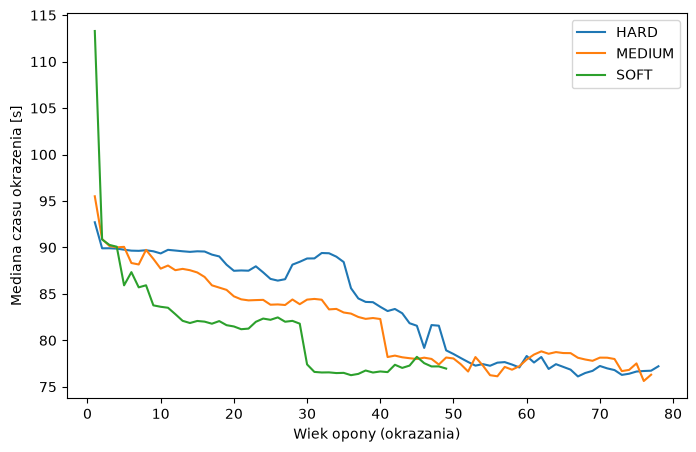

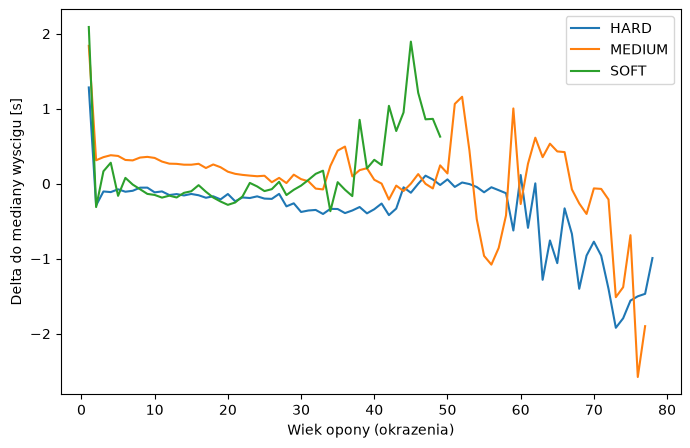

In [5]:
import os 
import pandas as pd 
import matplotlib.pyplot as plt 
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg2://f1:f1@localhost:5432/f1")
df = pd.read_sql("SELECT * FROM laps", engine)
df = df[df["compound"].isin(["SOFT", "MEDIUM", "HARD"])]
print(df.shape)
print(df.describe)

fig, ax = plt.subplots(figsize=(8,5))
for comp, g in df.groupby("compound"):
    m = g.groupby("tyre_life")["lap_time_s"].median()
    ax.plot(m.index , m.values, label=comp)
ax.set_xlabel("Wiek opony (okrazania)")
ax.set_ylabel("Mediana czasu okrazenia [s]")
ax.legend()
plt.show()

df["lap_delta"] = df["lap_time_s"] - df.groupby(["year", "gp"])["lap_time_s"].transform("median")
fig, ax = plt.subplots(figsize=(8,5))
for comp, g in df.groupby("compound"):
    m = g.groupby("tyre_life")["lap_delta"].median()
    ax.plot(m.index, m.values, label=comp)
ax.set_xlabel("Wiek opony (okrazenia)")
ax.set_ylabel("Delta do mediany wyscigu [s]")
ax.legend()
plt.show()

In [9]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg2://f1:f1@localhost:5432/f1")
df = pd.read_sql("SELECT * FROM laps", engine)
df = df[df["compound"].isin(["SOFT", "MEDIUM", "HARD"])]
df["driver_median"] = df.groupby(["year", "gp", "driver"])["lap_time_s"].transform("median")
df["delta_s"] = df["lap_time_s"] - df["driver_median"]

worst =[(2025, "British Grand Prix"), (2023,"British Grand Prix"),
        (2025, "Australian Grand Prix"), (2024, "Canadian Grand Prix")]

for y, gp in worst:
    g = df[(df.year==y) & (df.gp == gp)]
    print(y,gp, "okrazen:" ,len(g), "| temp toru:", g.track_temp.min(), "-", g.track_temp.max())
    print(g.groupby(pd.cut(g["lap_number"], 6), observed=True)["delta_s"].median().round(2).to_string(), "\n")

2025 British Grand Prix okrazen: 120 | temp toru: 23.6 - 24.6
lap_number
(43.992, 45.333]    2.22
(45.333, 46.667]    1.06
(46.667, 48.0]     -0.11
(48.0, 49.333]     -0.50
(49.333, 50.667]   -0.60
(50.667, 52.0]     -0.09 

2023 British Grand Prix okrazen: 801 | temp toru: 27.7 - 33.3
lap_number
(0.949, 9.5]    0.69
(9.5, 18.0]     0.44
(18.0, 26.5]   -0.01
(26.5, 35.0]   -0.16
(35.0, 43.5]   -1.27
(43.5, 52.0]   -1.25 

2025 Australian Grand Prix okrazen: 28 | temp toru: 19.3 - 19.3
lap_number
(41.999, 42.167]    0.85
(42.833, 43.0]     -0.85 

2024 Canadian Grand Prix okrazen: 176 | temp toru: 25.7 - 28.5
lap_number
(47.978, 51.667]    1.75
(55.333, 59.0]      2.80
(59.0, 62.667]      0.47
(62.667, 66.333]   -0.14
(66.333, 70.0]     -0.55 



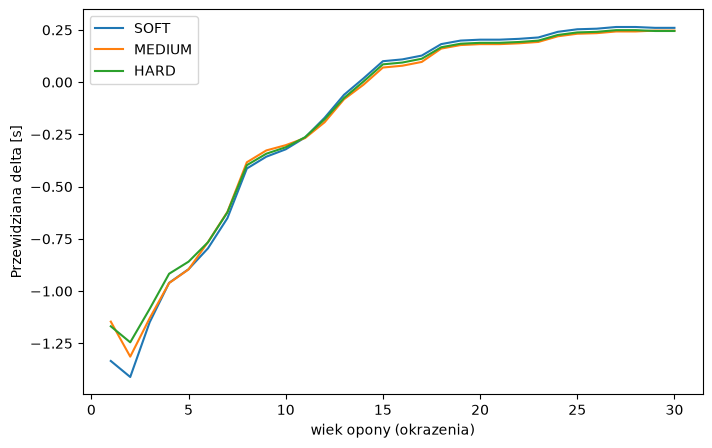

In [13]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt

model = joblib.load("../models/tyre_model.joblib")
total = 57

fig, ax = plt.subplots(figsize=(8,5))
for comp in ["SOFT", "MEDIUM", "HARD"]:
    rows = [dict(compound=comp, gp="Bahrain Grand Prix", tyre_life=t, lap_number = 35,
                 laps_remaining = 22, track_temp=35.0, air_temp=26.0)
                 for t in range(1,31)]

    ax.plot(range(1,31), model.predict(pd.DataFrame(rows)), label=comp)

ax.set_xlabel("wiek opony (okrazenia)")
ax.set_ylabel("Przewidziana delta [s]")
ax.legend()
plt.show()